# Task 1 – NVDA, AVGO, MU, SNDK: performance over the last 6 months

Each stock is shown as **percentage change from its first close** in the period, so all four start at 0% and can be compared directly. Data: daily close prices from Yahoo Finance (`yfinance`), adjusted for splits and dividends.

In [1]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

TICKERS = ["NVDA", "AVGO", "MU", "SNDK"]
PERIOD = "6mo"

raw = yf.download(TICKERS, period=PERIOD, auto_adjust=True, progress=False)
close = raw["Close"][TICKERS].dropna(how="all")
close.to_csv("task1_close_prices.csv")          # keep the raw data
print(f"{close.index[0].date()} to {close.index[-1].date()}, {len(close)} trading days")
close.tail()

2026-04-20 to 2026-10-19, 127 trading days


Ticker,NVDA,AVGO,MU,SNDK
Date,,,,
2026-10-13,228.520004,357.309998,953.040039,1482.329956
2026-10-14,221.300003,346.250000,914.130005,1403.339966
2026-10-15,217.229996,344.329987,931.239990,1394.829956
2026-10-16,214.130005,328.750000,878.840027,1299.300049
2026-10-19,218.445007,338.788300,925.510010,1403.199951


In [2]:
# percentage change relative to the first available close of each stock
pct = (close / close.bfill().iloc[0] - 1) * 100

summary = pd.DataFrame({
    "first close": close.bfill().iloc[0],
    "last close": close.ffill().iloc[-1],
    "change %": pct.ffill().iloc[-1],
    "max %": pct.max(),
    "min %": pct.min(),
    "drawdown from peak %": ((close / close.cummax() - 1) * 100).ffill().iloc[-1],
}).round(1)
summary

,first close,last close,change %,max %,min %,drawdown from peak %
Ticker,,,,,,
NVDA,201.6,218.4,8.4,18.7,-5.9,-8.7
AVGO,398.3,338.8,-14.9,20.5,-17.5,-29.4
MU,448.3,925.5,106.5,170.6,0.0,-23.7
SNDK,913.0,1403.2,53.7,155.7,-1.0,-39.9


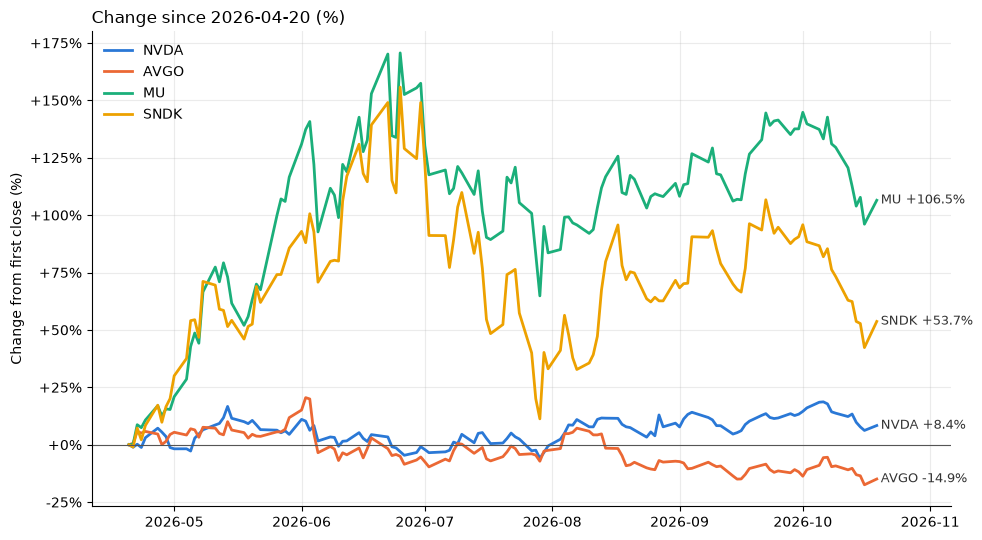

In [3]:
COLORS = {"NVDA": "#2a78d6", "AVGO": "#eb6834", "MU": "#1baf7a", "SNDK": "#eda100"}

fig, ax = plt.subplots(figsize=(10, 5.5))
for t in TICKERS:
    s = pct[t].dropna()
    ax.plot(s.index, s.values, color=COLORS[t], lw=2, label=t)
    ax.annotate(f" {t} {s.iloc[-1]:+.1f}%", (s.index[-1], s.iloc[-1]), va="center", fontsize=9, color="#333")

ax.axhline(0, color="#555", lw=0.8)
ax.set_title(f"Change since {pct.index[0].date()} (%)", loc="left")
ax.set_ylabel("Change from first close (%)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:+.0f}%")
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
ax.set_xlim(right=pct.index[-1] + pd.Timedelta(days=18))     # space for the end labels
plt.tight_layout()
plt.savefig("task1_six_month_performance.png", dpi=150)
plt.show()

**How to read it:** the two memory companies (MU, SNDK) rose strongly, while the two compute companies (NVDA, AVGO) went sideways or fell. The `drawdown from peak` column shows how far each stock is below its highest close in the period. For MU and SNDK it shows how much of the gain was lost in the recent memory sell-off.

Note: the prices in the task were given in round numbers, so they can differ a little from these closes, depending on the exact day.

## Volatility and the size of normal moves (Task 1, section 3.1)

**Realized volatility** = standard deviation of daily log returns, annualized with √252 (trading days per year).

If log returns are approx. normal with annual volatility $\sigma$, the log return over $T$ years has standard deviation $\sigma\sqrt{T}$. A **1-standard-deviation range** for the price is then

$$P_0 \cdot e^{-\sigma\sqrt{T}} \quad \text{to} \quad P_0 \cdot e^{+\sigma\sqrt{T}}$$

This range is not symmetric in %: the upside is larger than the downside (e.g. for $\sigma\sqrt{T}$ = 0.5: +65% / −39%). Approx. 68% of outcomes fall inside it if the model holds; real returns have fatter tails.

I use two windows: the **6-month** window (same as the chart) and the last **20 days** (the current regime). For a real forecast of future volatility, the options market's **implied volatility** is better, because it looks forward.

In [4]:
import numpy as np

logret = np.log(close).diff()
vol_6m  = logret.std() * np.sqrt(252)                 # annualized, full 6-month window
vol_20d = logret.tail(20).std() * np.sqrt(252)        # annualized, last 20 trading days

last = close.ffill().iloc[-1]
rows = {}
for t in TICKERS:
    s = vol_6m[t]
    r = {"vol 6m (ann.) %": s * 100, "vol 20d (ann.) %": vol_20d[t] * 100}
    for label, T in [("6m", 0.5), ("12m", 1.0)]:
        m = s * np.sqrt(T)
        r[f"{label}: -1σ %"] = (np.exp(-m) - 1) * 100
        r[f"{label}: +1σ %"] = (np.exp(m) - 1) * 100
        r[f"{label}: price range"] = f"{last[t] * np.exp(-m):,.0f} – {last[t] * np.exp(m):,.0f}"
    rows[t] = r
vol_table = pd.DataFrame(rows).T
vol_table.round(1)

,vol 6m (ann.) %,vol 20d (ann.) %,6m: -1σ %,6m: +1σ %,6m: price range,12m: -1σ %,12m: +1σ %,12m: price range
NVDA,38.924186,24.462016,-24.060678,31.684083,166 – 288,-32.242963,47.586146,148 – 322
AVGO,47.134353,38.069994,-28.343778,39.555223,243 – 473,-37.583687,60.214527,211 – 543
MU,90.067786,51.313822,-47.105743,89.056443,"490 – 1,750",-59.370585,146.127095,"376 – 2,278"
SNDK,112.573368,63.136822,-54.88764,121.668741,"633 – 3,110",-67.558564,208.247758,"455 – 4,325"


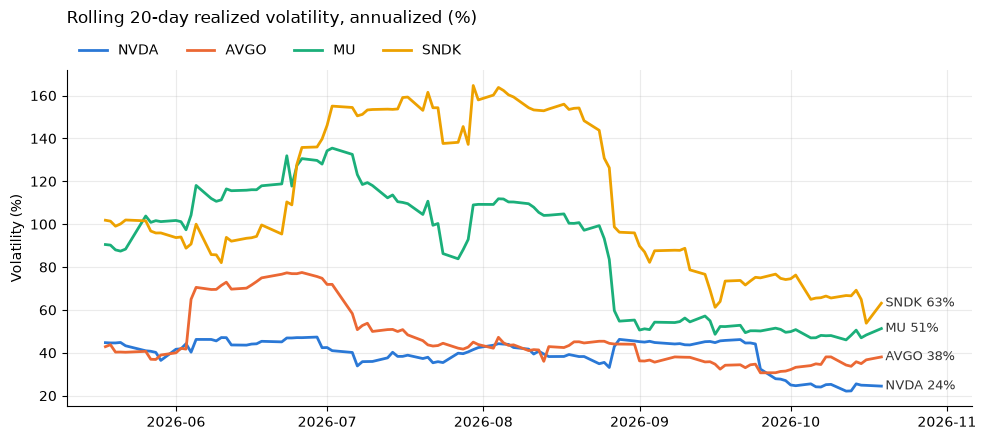

In [5]:
roll = logret.rolling(20).std() * np.sqrt(252) * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
for t in TICKERS:
    s = roll[t].dropna()
    ax.plot(s.index, s.values, color=COLORS[t], lw=2, label=t)
    ax.annotate(f" {t} {s.iloc[-1]:.0f}%", (s.index[-1], s.iloc[-1]), va="center", fontsize=9, color="#333")
ax.set_title("Rolling 20-day realized volatility, annualized (%)", loc="left", pad=34)
ax.set_ylabel("Volatility (%)")
ax.grid(alpha=0.25); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=4)
ax.set_xlim(right=roll.index[-1] + pd.Timedelta(days=18))
plt.tight_layout(); plt.savefig("task1_rolling_vol.png", dpi=150); plt.show()

**How to use this in the answer:** compare a stock's move with its own 1σ range. A +40% move for a stock with 70% volatility is approx. one standard deviation, so it is **normal noise**, not proof of a trend. A move far outside the range (2σ or more) needs a real explanation. Also compare the 20-day vol with the 6-month vol: if the recent vol is much higher, the market is in a more nervous regime (for example the memory sell-off in October).